<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/19-sequences-and-transformers/01_lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 19: Sequences and Transformers

ChatGPT, Gemini, Llama and the other large language models are, at their core, programs that do one thing: given some text, predict what comes next. They're built from a design called the **transformer**, introduced in 2017 in a paper called *Attention Is All You Need*, and its central idea, **attention**, fits in about ten lines of code.

In this module you'll build that machinery yourself, from the ground up, and train a small GPT ("generative pretrained transformer") that writes in the style of Shakespeare. It's the same kind of model as the big ones, only thousands of times smaller, so it trains on an ordinary CPU in a couple of minutes.

**Contents**

1. Predicting the next character
2. Tokenisation
3. A model that counts
4. Embeddings
5. Context: looking further back
6. Attention from scratch
7. Queries, keys and values
8. Multi-head attention and positions
9. The transformer block
10. A small GPT
11. Generating text: temperature and top-k
12. Looking inside
13. From here to ChatGPT

In [1]:
import collections
import math
import re
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from torch import nn

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/19-sequences-and-transformers/data/tiny_shakespeare.txt"
local = Path("data/tiny_shakespeare.txt")
if local.exists():
    text = local.read_text(encoding="utf-8")
else:
    import urllib.request
    text = urllib.request.urlopen(DATA_URL).read().decode("utf-8")

print("PyTorch", torch.__version__)
_ = torch.manual_seed(0)

PyTorch 2.15.0+cu132


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

The lesson runs on a CPU in a few minutes, most of it spent training the GPT in Section 10.

## 1. Predicting the next character

Our data is **Tiny Shakespeare**: about 40,000 lines from Shakespeare's plays, joined into one long text file of a little over a million characters. It was put together by Andrej Karpathy for teaching, and it's become the standard first dataset for language models.

In [3]:
print(f"{len(text):,} characters\n")
print(text[:400])

1,115,394 characters

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it 


A **language model** assigns probabilities to what comes next. Given "First Citize", a good model should put a high probability on "n". Given "To be, or not to", it should strongly expect " be". Once you have such a model, you can **generate** text: pick a next character according to its probabilities, add it to the text, and repeat.

That's all a large language model does when it answers a question. The answer is produced one piece at a time, each piece chosen from the probabilities the model gives for what comes next. Everything else, including the impression of understanding, comes from making those predictions extremely good.

## 2. Tokenisation

Networks work with numbers, so the text first has to be split into pieces called **tokens**, and each token given a number. The simplest choice is one token per character:

In [4]:
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}        # string to integer
itos = {i: c for c, i in stoi.items()}            # integer to string


def encode(s):
    return [stoi[c] for c in s]


def decode(ids):
    return "".join(itos[i] for i in ids)


print(f"{len(chars)} different characters: {''.join(chars)!r}")
print(encode("To be, or not to be"))
print(decode(encode("To be, or not to be")))

65 different characters: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
[32, 53, 1, 40, 43, 6, 1, 53, 56, 1, 52, 53, 58, 1, 58, 53, 1, 40, 43]
To be, or not to be


65 characters is a tiny vocabulary, and any text can be written with it. The cost is that sequences are long: every word takes several tokens, and the model must learn spelling before it can learn anything else.

The opposite choice is one token per **word**. Sequences get much shorter, but the vocabulary explodes, and any word not seen in training (a name, a typo, a new word) can't be represented at all.

In [5]:
words = re.findall(r"[A-Za-z']+", text)
print(f"{len(words):,} words, {len(set(words)):,} different ones")
counts = collections.Counter(words)
print(f"{sum(1 for w in counts if counts[w] == 1):,} words appear only once, for example: {[w for w in counts if counts[w] == 1][:8]}")

204,062 words, 14,554 different ones
6,893 words appear only once, for example: ['relieved', 'humanely', 'afflicts', 'inventory', 'particularise', 'rakes', 'commonalty', 'maliciously']


Modern language models use something in between: **subword** tokens, learnt with an algorithm called **byte-pair encoding (BPE)**. It starts from single characters and repeatedly finds the most common pair of neighbouring tokens and merges it into a new token. Common words end up as one token, rare words are split into familiar pieces, and nothing is ever unknown, because the single characters are still there.

Here's BPE from scratch. Like real tokenisers, it first splits the text into chunks (a word with its leading space, or a run of punctuation) and never merges across them, which also makes it fast: it only has to work on each **distinct** chunk once, weighted by how often it appears.

In [6]:
def train_bpe(text, n_merges):
    chunks = collections.Counter(re.findall(r" ?[A-Za-z]+| ?[0-9]+| ?[^A-Za-z0-9\s]+|\s+", text))
    split = {chunk: tuple(chunk) for chunk in chunks}             # every chunk starts as single characters
    merges = []
    for _ in range(n_merges):
        pairs = collections.Counter()
        for chunk, n in chunks.items():
            pieces = split[chunk]
            for pair in zip(pieces, pieces[1:]):
                pairs[pair] += n
        best = max(pairs, key=lambda p: (pairs[p], p))             # most frequent pair (ties: a fixed order)
        merges.append(best)
        for chunk in chunks:
            pieces, out, i = split[chunk], [], 0
            while i < len(pieces):
                if i + 1 < len(pieces) and (pieces[i], pieces[i + 1]) == best:
                    out.append(pieces[i] + pieces[i + 1])
                    i += 2
                else:
                    out.append(pieces[i])
                    i += 1
            split[chunk] = tuple(out)
    n_tokens = sum(len(split[c]) * n for c, n in chunks.items())
    return merges, split, n_tokens


start = time.time()
merges, split, n_tokens = train_bpe(text, 200)
print(f"200 merges learnt in {time.time() - start:.0f} seconds")
print("first 15 merges:", ["".join(m) for m in merges[:15]])
print("last 10 merges: ", ["".join(m) for m in merges[-10:]])
print(f"\n{len(text):,} characters become {n_tokens:,} tokens: {len(text) / n_tokens:.2f} characters per token")

200 merges learnt in 7 seconds
first 15 merges: [' t', 'he', ' a', 'ou', ' s', ' m', 'in', ' w', 're', 'ha', 'nd', ' the', ' b', 'is', 'or']
last 10 merges:  [' good', 'row', 'ine', 'ath', ' lord', 'hich', 'nt', 'ust', 'one', ' pr']

1,115,394 characters become 599,752 tokens: 1.86 characters per token


The first merges are the most common pairs in English: a space followed by "t", "h" followed by "e", then " the" as a whole. After 200 merges, frequent short words and word endings have their own tokens, and the text needs only a little over half as many tokens as characters.

To tokenise a new piece of text, apply the learnt merges in the same order:

In [7]:
def bpe_tokenise(word, merges):
    pieces = list(word)
    for a, b in merges:
        i, out = 0, []
        while i < len(pieces):
            if i + 1 < len(pieces) and pieces[i] == a and pieces[i + 1] == b:
                out.append(a + b)
                i += 2
            else:
                out.append(pieces[i])
                i += 1
        pieces = out
    return pieces


for word in [" the", " king", " thousand", " unthinkable", " Pythonista"]:
    print(f"{word!r:>16} -> {bpe_tokenise(word, merges)}")

          ' the' -> [' the']
         ' king' -> [' k', 'ing']
     ' thousand' -> [' thou', 's', 'and']
  ' unthinkable' -> [' u', 'n', 'th', 'in', 'k', 'a', 'b', 'le']
   ' Pythonista' -> [' ', 'P', 'y', 'th', 'on', 'is', 't', 'a']


Common words become one or two tokens; a word Shakespeare never wrote, like "Pythonista", is still tokenised, just into smaller pieces. GPT-style tokenisers do exactly this with a vocabulary of 50,000 to 200,000 tokens learnt from a huge amount of text, and they work on bytes rather than characters, so that any language, emoji or file can be represented.

Tokenisation explains some famous quirks of language models. A model that sees " strawberry" as two or three tokens never directly sees its letters, which is one reason models have been bad at counting the r's in it. And numbers split into irregular chunks make arithmetic harder, which the mini project explores.

For the rest of the lesson we use characters: with only 65 tokens, the model is small and fast to train, and the results are easy to read.

In [8]:
data = torch.tensor(encode(text), dtype=torch.long)
n_train = int(0.9 * len(data))
train_data, valid_data = data[:n_train], data[n_train:]
vocab_size = len(chars)
print(f"training tokens {len(train_data):,}, validation tokens {len(valid_data):,}")

training tokens 1,003,854, validation tokens 111,540


The last 10% of the text is kept for validation. It's taken from the end rather than at random, so the validation text is a passage the model has never seen, not scattered sentences whose neighbours it trained on.

## 3. A model that counts

The simplest language model predicts the next character from the current one only: a **bigram model**. It needs no training in the usual sense, just counting. For every pair of neighbouring characters in the training text, add one to a 65 x 65 table, then turn each row into probabilities:

In [9]:
counts = torch.zeros(vocab_size, vocab_size)
counts.index_put_((train_data[:-1], train_data[1:]), torch.ones(len(train_data) - 1), accumulate=True)
bigram = (counts + 1) / (counts + 1).sum(dim=1, keepdim=True)        # add 1 to every count, so nothing is impossible

after_q = bigram[stoi["q"]]
print("after 'q':", [(itos[i], round(p, 3)) for p, i in zip(*[t.tolist() for t in after_q.topk(3)])])
after_space = bigram[stoi[" "]]
print("after ' ':", [(itos[i], round(p, 3)) for p, i in zip(*[t.tolist() for t in after_space.topk(5)])])

after 'q': [('u', 0.898), ('d', 0.002), ('e', 0.002)]
after ' ': [('t', 0.141), ('a', 0.079), ('s', 0.071), ('h', 0.071), ('m', 0.062)]


After "q" comes "u", almost always. After a space, the most likely next letters are the starts of common words.

How good is a language model? The standard measure is the **cross-entropy** on text it hasn't seen: the average of `-log(probability given to the character that actually came next)`. Lower is better. A model that knows nothing and gives every character the same probability scores `log(65) = 4.17`.

In [10]:
def bigram_loss(tokens):
    return -torch.log(bigram[tokens[:-1], tokens[1:]]).mean().item()


print(f"knowing nothing:        {math.log(vocab_size):.3f}")
print(f"bigram, training text:  {bigram_loss(train_data):.3f}")
print(f"bigram, validation:     {bigram_loss(valid_data):.3f}")

knowing nothing:        4.174
bigram, training text:  2.455
bigram, validation:     2.482


You'll also see **perplexity**, which is `exp(cross-entropy)`. It can be read as "the model is as unsure as if it were choosing uniformly between this many characters": 65 for knowing nothing, about 12 for the bigram model.

Let's generate some text with it, starting from a new line:

In [11]:
def generate_bigram(n, seed=0):
    g = torch.Generator().manual_seed(seed)
    ids = [stoi["\n"]]
    for _ in range(n):
        ids.append(torch.multinomial(bigram[ids[-1]], 1, generator=g).item())
    return decode(ids)


print(generate_bigram(300))


th remofed hexpselteredoca meaman youd INAlste grecofurey h fotherere hath thig berelisseanongilost.
tho y we w ke RYORD:
Widarthofr nd; my f tsoo we w y mer aim whioervoto,
Pre co n s uzed
I s h. fo INVeprf pllie-milyompofond ssay eint odeld fleome igle inkee he t,
As toinobo y tonesthast st hayowa


It has the rhythm of text, word-length chunks and capitals after new lines, but no words. With only one character of memory, it can't spell. A good model needs **context**: the further back it can look, the better its predictions can be.

## 4. Embeddings

Before adding context, one building block. Neural networks don't take token numbers directly: token 46 isn't "more" than token 45. Instead, each token gets a vector of learnt numbers, its **embedding**, stored as one row of a table. `nn.Embedding` is that table:

In [12]:
emb = nn.Embedding(vocab_size, 8)          # a 65 x 8 table of learnt numbers
ids = torch.tensor(encode("hello"))
print("ids:", ids.tolist(), "->", tuple(emb(ids).shape))
print("the same as picking rows:", torch.equal(emb(ids), emb.weight[ids]))

ids: [46, 43, 50, 50, 53] -> (5, 8)
the same as picking rows: True


Looking up a row is the same as multiplying a one-hot vector (all zeros except a 1 in the token's position) by the table, so an embedding is just a linear layer with a fast shortcut.

In fact, an embedding table of size 65 x 65, whose rows are used directly as the logits for the next character, **is** a bigram model. Trained with cross-entropy, it should learn the same probabilities as counting:

In [13]:
torch.manual_seed(0)
bigram_net = nn.Embedding(vocab_size, vocab_size)
optimizer = torch.optim.Adam(bigram_net.parameters(), lr=0.1)
for step in range(300):
    logits = bigram_net(train_data[:-1])
    loss = F.cross_entropy(logits, train_data[1:])
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
with torch.no_grad():
    valid_loss = F.cross_entropy(bigram_net(valid_data[:-1]), valid_data[1:]).item()
print(f"trained bigram network, validation loss {valid_loss:.3f}   (counting gave {bigram_loss(valid_data):.3f})")

trained bigram network, validation loss 2.485   (counting gave 2.482)


The same answer, found by gradient descent instead of counting. Counting only works for this simplest case; gradient descent works for any model we can write down, which is why everything from here on is trained that way.

In real models the embeddings are much smaller than the vocabulary (here we'll use 128 numbers per token), and training tends to place tokens that behave alike close together in that space.

## 5. Context: looking further back

To predict well, a model must use many previous tokens, and that raises a design question: how do you combine a varying number of previous tokens into one prediction?

- A **fixed window** (concatenate the embeddings of the last, say, 8 tokens and feed them to an MLP) works, but the window is small and every position has separate weights.
- A **recurrent neural network (RNN)** reads the text one token at a time, updating a memory vector as it goes. It can in principle use unlimited context, but it must process tokens strictly in order, which is slow on GPUs, and in practice information from far back fades.
- **Attention** lets every position look directly at every earlier position, all at once, and decide for itself which ones matter. That's what transformers use.

We'll build attention in three steps. Training data for all of them is the same: chunks of text of length `block_size`, where the target at each position is the next character. One chunk gives `block_size` training examples at once:

In [14]:
block_size = 64
x = train_data[:block_size]
y = train_data[1:block_size + 1]
for t in range(5):
    print(f"context {decode(x[:t + 1].tolist())!r:<10} -> next {decode([y[t].item()])!r}")


def get_batch(split, batch_size=32, generator=None):
    source = train_data if split == "train" else valid_data
    starts = torch.randint(len(source) - block_size - 1, (batch_size,), generator=generator)
    x = torch.stack([source[s:s + block_size] for s in starts])
    y = torch.stack([source[s + 1:s + block_size + 1] for s in starts])
    return x, y


xb, yb = get_batch("train", generator=torch.Generator().manual_seed(0))
print("\nbatch shapes:", tuple(xb.shape), tuple(yb.shape))

context 'F'        -> next 'i'
context 'Fi'       -> next 'r'
context 'Fir'      -> next 's'
context 'Firs'     -> next 't'
context 'First'    -> next ' '

batch shapes: (32, 64) (32, 64)


## 6. Attention from scratch

Start with the simplest way to combine context: at each position, take the **average** of the vectors at that position and every earlier one. Never later ones: when predicting the next character, the model mustn't peek at the future, or training would be trivially easy and generation impossible.

A loop makes the idea clear. Then the same thing as one matrix multiplication:

In [15]:
torch.manual_seed(0)
T, D = 5, 3
v = torch.randn(T, D)                       # one vector per position

averaged_loop = torch.stack([v[:t + 1].mean(dim=0) for t in range(T)])

weights = torch.tril(torch.ones(T, T))      # lower triangle: position t sees positions 0..t
weights = weights / weights.sum(dim=1, keepdim=True)
averaged_matrix = weights @ v

print(weights)
print("same result:", torch.allclose(averaged_loop, averaged_matrix))

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000]])
same result: True


Row `t` of the weight matrix says how much each position contributes to position `t`: equal shares of everything up to `t`, zero for the future. Multiplying by `v` mixes the vectors in those proportions.

The same weights can be made with a **softmax**. Set the future positions to minus infinity (so their `exp` is exactly 0) and the rest to 0 (so they share equally):

In [16]:
scores = torch.zeros(T, T)
future = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)     # True above the diagonal
scores = scores.masked_fill(future, float("-inf"))
print(torch.softmax(scores, dim=1))

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000]])


This is the form we want, because now the zeros in `scores` can be replaced by **any** numbers. Large scores mean "pay a lot of attention to this position", and the softmax turns them into weights that are positive and add up to 1, with the mask still blocking the future. The question is where the scores come from.

## 7. Queries, keys and values

In attention, the scores are computed **from the data**. Every position produces three vectors from its own embedding, each with its own learnt linear layer:

- a **query**: "what am I looking for?"
- a **key**: "what do I contain?"
- a **value**: "what will I pass on if someone attends to me?"

The score between position `t` and an earlier position `s` is the dot product of `t`'s query with `s`'s key: high when they match. After the mask and softmax, position `t` collects a weighted average of the **values**. A vowel might look for the previous consonant; the start of a word might look for the previous word; and since the layers are learnt, the network decides what to look for.

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^\top}{\sqrt{d}} + \text{mask}\right) V$$

In [17]:
def attention(q, k, v):
    """Causal scaled dot-product attention. q, k, v: (..., T, d)."""
    d = q.shape[-1]
    scores = q @ k.transpose(-2, -1) / math.sqrt(d)                          # (..., T, T)
    t = q.shape[-2]
    future = torch.triu(torch.ones(t, t, dtype=torch.bool, device=q.device), diagonal=1)
    weights = torch.softmax(scores.masked_fill(future, float("-inf")), dim=-1)
    return weights @ v, weights


torch.manual_seed(0)
x = torch.randn(2, 6, 16)                       # a batch of 2 sequences, 6 positions, 16 numbers each
to_q, to_k, to_v = nn.Linear(16, 16, bias=False), nn.Linear(16, 16, bias=False), nn.Linear(16, 16, bias=False)
out, weights = attention(to_q(x), to_k(x), to_v(x))
print("output", tuple(out.shape), "  attention weights", tuple(weights.shape))
print(weights[0].detach().numpy().round(2))

built_in = F.scaled_dot_product_attention(to_q(x), to_k(x), to_v(x), is_causal=True)
print("matches PyTorch's built-in attention:", torch.allclose(out, built_in, atol=1e-6))

output (2, 6, 16)   attention weights (2, 6, 6)
[[1.   0.   0.   0.   0.   0.  ]
 [0.37 0.63 0.   0.   0.   0.  ]
 [0.23 0.41 0.36 0.   0.   0.  ]
 [0.18 0.06 0.12 0.65 0.   0.  ]
 [0.14 0.27 0.26 0.16 0.17 0.  ]
 [0.1  0.14 0.15 0.19 0.23 0.19]]
matches PyTorch's built-in attention: True


Each row of the weight matrix still adds up to 1 and still has zeros above the diagonal, but the weights are no longer equal: they depend on the content. PyTorch's `F.scaled_dot_product_attention` gives the same answer, using faster code.

Why divide by `sqrt(d)`? A dot product of two random vectors with `d` entries grows with `d`: its standard deviation is about `sqrt(d)`. Without the scaling, large vectors give huge scores, the softmax puts almost all the weight on one position, and the gradients for every other position vanish:

In [18]:
for d in [16, 256]:
    q, k = torch.randn(1, 8, d), torch.randn(1, 8, d)
    raw = (q @ k.transpose(-2, -1))[0, -1]
    print(f"d = {d:>3}: largest softmax weight without scaling {torch.softmax(raw, -1).max():.3f}, "
          f"with scaling {torch.softmax(raw / math.sqrt(d), -1).max():.3f}")

d =  16: largest softmax weight without scaling 0.929, with scaling 0.514
d = 256: largest softmax weight without scaling 1.000, with scaling 0.367


With the scaling, the weights stay spread out enough to learn from, whatever the size of the vectors.

## 8. Multi-head attention and positions

One set of queries and keys can only look for one kind of thing at a time. **Multi-head attention** runs several attentions side by side, each on a slice of the vector, and joins their outputs: with 4 heads and 128 numbers, each head works with 32. One head might track the previous character, another the start of the current word, another the speaker's name. A final linear layer mixes the heads' outputs.

In [19]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)          # queries, keys and values for all heads at once
        self.proj = nn.Linear(d_model, d_model)             # mixes the heads' outputs

    def forward(self, x, return_weights=False):
        b, t, d = x.shape
        q, k, v = self.qkv(x).split(d, dim=2)
        # (b, t, d) -> (b, heads, t, d / heads): each head gets its own slice
        q, k, v = (z.view(b, t, self.n_heads, d // self.n_heads).transpose(1, 2) for z in (q, k, v))
        out, weights = attention(q, k, v)
        out = out.transpose(1, 2).reshape(b, t, d)           # join the heads again
        return (self.proj(out), weights) if return_weights else self.proj(out)


mha = MultiHeadAttention(d_model=128, n_heads=4)
print(tuple(mha(torch.randn(2, 64, 128)).shape), f"  parameters: {sum(p.numel() for p in mha.parameters()):,}")

(2, 64, 128)   parameters: 66,048


There's one thing attention can't see: **order**. The scores depend only on the content of the vectors, so if you shuffled the earlier positions, each position would get the same weighted average. "Dog bites man" and "man bites dog" would look alike. The fix is to add a **position embedding** to each token's embedding: a second learnt table, indexed by the position (0 to `block_size - 1`) instead of the token. The original transformer used fixed patterns of sines and cosines instead (Exercise 8); GPT-2 learnt its position table, and so do we.

## 9. The transformer block

A transformer is a stack of identical **blocks**. Each block has two parts:

1. **Attention**, where positions exchange information ("communication").
2. A small **MLP**, applied to each position separately, where each position processes what it has gathered ("computation"). It widens the vector to 4 times its size, applies a GELU (a smooth version of ReLU), and narrows it back.

Both parts use two tricks from Modules 17 and 18: a **residual connection** (each part adds a correction to its input instead of replacing it) and **layer normalisation**, which rescales each position's vector to mean 0 and standard deviation 1 (like batch norm, but within one example, so it works the same for any batch size). GPT-2 and most models since apply it at the start of each part ("pre-norm"):

In [20]:
class Block(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))       # communicate
        x = x + self.mlp(self.ln2(x))        # compute
        return x


block = Block(128, 4)
print(f"one block: {sum(p.numel() for p in block.parameters()):,} parameters")

one block: 198,272 parameters


## 10. A small GPT

A GPT is: token embeddings plus position embeddings, a stack of blocks, a final layer norm, and a linear layer that turns each position's vector into logits for the next token.

In [21]:
class GPT(nn.Module):
    def __init__(self, vocab_size, block_size, d_model=128, n_heads=4, n_layers=4):
        super().__init__()
        self.block_size = block_size
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)
        self.blocks = nn.Sequential(*[Block(d_model, n_heads) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx):
        t = idx.shape[1]
        x = self.token_emb(idx) + self.pos_emb(torch.arange(t, device=idx.device))
        return self.head(self.ln(self.blocks(x)))            # (batch, t, vocab_size) logits


torch.manual_seed(0)
model = GPT(vocab_size, block_size)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")
logits = model(xb)
print("logits", tuple(logits.shape), f"  initial loss {F.cross_entropy(logits.flatten(0, 1), yb.flatten()).item():.3f}"
      f"  (knowing nothing: {math.log(vocab_size):.3f})")

parameters: 818,241
logits (32, 64, 65)   initial loss 4.334  (knowing nothing: 4.174)


About 800,000 parameters. GPT-2's smallest version had 124 million, and today's largest models have hundreds of billions, but the structure is the same. The initial loss is close to `log(65)`, as it should be for an untrained network (the debugging check from Module 17).

Training is the usual loop. Each step takes a batch of 32 random chunks of 64 characters, so every step trains on 2,048 next-character predictions at once. AdamW with a one-cycle schedule, 1,500 steps:

In [22]:
@torch.no_grad()
def estimate_loss(model, split, batches=8):
    model.eval()
    g = torch.Generator().manual_seed(1)              # the same batches every time
    losses = [F.cross_entropy(model(x).flatten(0, 1), y.flatten()).item()
              for x, y in (get_batch(split, 64, g) for _ in range(batches))]
    model.train()
    return sum(losses) / len(losses)


steps = 1500
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, total_steps=steps, pct_start=0.1)
batch_generator = torch.Generator().manual_seed(0)
history, start = [], time.time()
for step in range(1, steps + 1):
    xb, yb = get_batch("train", generator=batch_generator)
    loss = F.cross_entropy(model(xb).flatten(0, 1), yb.flatten())
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    scheduler.step()
    if step % 100 == 0:
        history.append((step, estimate_loss(model, "train"), estimate_loss(model, "valid")))
        if step % 300 == 0:
            print(f"step {step:>4}: train {history[-1][1]:.3f}   validation {history[-1][2]:.3f}   ({time.time() - start:.0f} s)")

step  300: train 1.983   validation 2.068   (26 s)


step  600: train 1.681   validation 1.827   (53 s)


step  900: train 1.541   validation 1.710   (80 s)


step 1200: train 1.457   validation 1.635   (109 s)


step 1500: train 1.433   validation 1.616   (139 s)


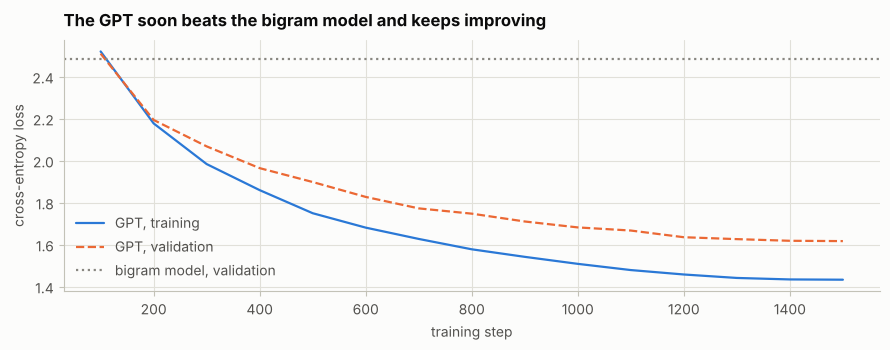

validation loss: bigram 2.482, GPT 1.616 (perplexity 12.0 -> 5.0)


In [23]:
s, tr, va = zip(*history)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(s, tr, color=PALETTE[0], label="GPT, training")
ax.plot(s, va, color=PALETTE[1], linestyle="--", label="GPT, validation")
ax.axhline(bigram_loss(valid_data), color=MUTED, linestyle=":", label="bigram model, validation")
ax.set_xlabel("training step")
ax.set_ylabel("cross-entropy loss")
ax.set_title("The GPT soon beats the bigram model and keeps improving")
ax.legend()
plt.tight_layout()
plt.show()
print(f"validation loss: bigram {bigram_loss(valid_data):.3f}, GPT {va[-1]:.3f} "
      f"(perplexity {math.exp(bigram_loss(valid_data)):.1f} -> {math.exp(va[-1]):.1f})")

The GPT passes the bigram model within the first few hundred steps and keeps improving. Its perplexity is less than half the bigram's: looking back up to 64 characters makes it much less unsure about what comes next. The validation loss is higher than the training loss, the usual gap, and it flattens out at the end as the learning rate decays to zero; more steps and a bigger model would push it further down.

Now the real test, generating text. The model only accepts up to `block_size` characters, so the context is cut to the last 64 at each step:

In [24]:
@torch.no_grad()
def generate(model, prompt, n_new, temperature=1.0, top_k=None, seed=0):
    model.eval()
    g = torch.Generator().manual_seed(seed)
    idx = torch.tensor([encode(prompt)])
    for _ in range(n_new):
        logits = model(idx[:, -model.block_size:])[:, -1, :] / temperature     # the prediction at the last position
        if top_k is not None:
            cutoff = logits.topk(top_k).values[:, -1:]
            logits = logits.masked_fill(logits < cutoff, float("-inf"))
        next_id = torch.multinomial(torch.softmax(logits, dim=-1), 1, generator=g)
        idx = torch.cat([idx, next_id], dim=1)
    return decode(idx[0].tolist())


print(generate(model, "ROMEO:\n", 400))

ROMEO:
Thy forms it wisely Warwick expant,
And gelse to you unwight now here hath good being some,
But the peace portill we all seedy that, none hath soon
Leavy me dain whice to gain! who nose well draw.

QUEEN ELIZABET
They thou shall are in come defering inle in me.

ESCALUS:
So, Sir; ClarELIUS:
The father,.
How downs, a do lies of love for show, will be a
stured is master? He kingdom of the like oldin


Compare that with the bigram model's output. The GPT has learnt the format of a play: speakers' names in capitals followed by a colon, lines of verse, punctuation. Most words are real English words, and some phrases almost make sense. It still invents words and the sentences don't hold together. That's the gap between 800,000 parameters trained for two minutes on one million characters, and billions of parameters trained for months on trillions of tokens.

## 11. Generating text: temperature and top-k

How the next token is chosen matters almost as much as the model. Two common controls:

- **Temperature** divides the logits before the softmax. Below 1, the probabilities become more peaked, and the text safer and more repetitive. Above 1, they flatten, and the text becomes more surprising and more error-prone. As the temperature approaches 0, sampling becomes "always pick the most likely token".
- **Top-k** keeps only the `k` most likely tokens and samples among them, cutting off the long tail of unlikely choices that produce nonsense.

In [25]:
for temperature in [0.5, 1.0, 1.5]:
    print(f"--- temperature {temperature} ---")
    print(generate(model, "JULIET:\n", 200, temperature=temperature, seed=1)[8:], "\n")
print("--- temperature 1.0, top-k 5 ---")
print(generate(model, "JULIET:\n", 200, top_k=5, seed=1)[8:])

--- temperature 0.5 ---


What such a prisonance that mean of your mother's care
And the desting a more, and long here in son,
That stay your death of your brother's too down:
A many lord, my son to the signest of the sent
Tha 

--- temperature 1.0 ---


But, suqueen, me us leave at a know accusison armine,
As a tickless, in Clifford of Gogains, we's not with
found our hight none cansishing at Ergard:
A grieve, what, say so resough eldisonerfu, it
Tha 

--- temperature 1.5 ---


But,
suqWere noblusil,' that's oby my shamself.'
DUKE VINTSTI3 GeRWTeir. LIFORD IV:
Gogaies, we's notgratoof, Leoor I knot none,
Masishions thErevers me your head,
Norman but sweigne's motecta, it reb 

--- temperature 1.0, top-k 5 ---


What stay an the caulties and honour to his prove,
But that word you traily stoop all thee the
shadon to me thee.

SICINIUS:
A beats are of there:
The has are the partain of soul to his present.

LUCI


At temperature 0.5 the text is cleaner but leans on the most common words and patterns. At 1.5 it falls apart into invented words. Chatbots usually use a temperature somewhat below 1, often combined with a cut-off like top-k or its relative **top-p** (keep the smallest set of tokens whose probabilities add up to `p`).

## 12. Looking inside

The attention weights show where each position looks. Here are the weights of all four heads in the first block for one line of text. Row `t` shows how position `t` divides its attention among positions 0 to `t`:

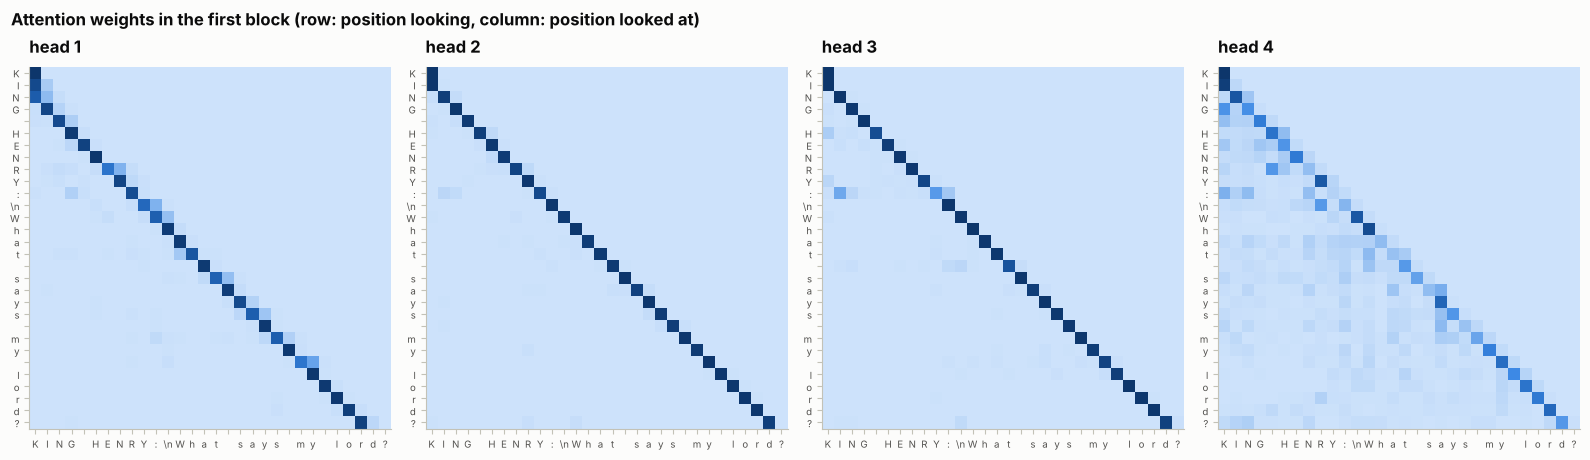

average weight on the same character, the previous one and the one before that:
head 1: same 0.01   1 back 0.09   2 back 0.86
head 2: same 0.01   1 back 0.96   2 back 0.01
head 3: same 0.01   1 back 0.94   2 back 0.00
head 4: same 0.06   1 back 0.48   2 back 0.05


In [26]:
line = "KING HENRY:\nWhat says my lord?"
idx = torch.tensor([encode(line)])
with torch.no_grad():
    x = model.token_emb(idx) + model.pos_emb(torch.arange(idx.shape[1]))
    _, weights = model.blocks[0].attn(model.blocks[0].ln1(x), return_weights=True)

labels = [c if c != "\n" else "\\n" for c in line]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6))
for h, ax in enumerate(axes):
    ax.imshow(weights[0, h], cmap="course_blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels)), labels, fontsize=7)
    ax.set_yticks(range(len(labels)), labels, fontsize=7)
    ax.grid(False)
    ax.set_title(f"head {h + 1}")
fig.suptitle("Attention weights in the first block (row: position looking, column: position looked at)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

print("average weight on the same character, the previous one and the one before that:")
for h in range(4):
    w = weights[0, h]
    same, back1, back2 = (torch.diagonal(w, offset=-k)[2 - k:].mean().item() for k in range(3))
    print(f"head {h + 1}: same {same:.2f}   1 back {back1:.2f}   2 back {back2:.2f}")

Everything is on or below the diagonal: the mask works, and no position looks into the future. Beyond that, the heads have specialised. Some put almost all their weight on one fixed offset, such as the previous character or the one before it, which is exactly what you need for spelling: they pass the last few letters forward so later layers can work with them. Others spread their attention more widely over the line, picking up characters such as spaces and punctuation that mark where words and lines begin. Nobody programmed these patterns; they were learnt because they help predict the next character.

Interpreting large models this way is a research field of its own (often called **mechanistic interpretability**). In real models the picture is much more complicated, but the starting point is the same: look at what the attention and the neurons respond to.

## 13. From here to ChatGPT

The model you trained has the same architecture as GPT-2 and, in outline, the large models used today. The differences are mostly scale and training:

| | this lesson | GPT-2 small (2019) | large models today |
|---|---|---|---|
| parameters | 0.8 million | 124 million | tens to hundreds of billions |
| tokens | 65 characters | 50,257 BPE tokens | 100,000 to 200,000+ BPE tokens |
| context | 64 tokens | 1,024 tokens | 100,000 tokens or more |
| training text | 1 million characters | about 40 GB of web pages | many trillions of tokens |
| training | 2 minutes on a CPU | days on many GPUs | months on thousands of GPUs |

Turning a pretrained text predictor into an assistant takes more steps. **Pretraining** on huge amounts of text gives a model that continues text; **instruction tuning** (fine-tuning on examples of questions and good answers) teaches it to respond helpfully; and **reinforcement learning from human (or AI) feedback** further shapes which answers it prefers. Module 20 picks up there, using pretrained models in practice.

A few engineering details also matter at scale. Attention compares every position with every earlier one, so its cost grows with the **square** of the context length, which is why long contexts are expensive. When generating, models keep the keys and values of earlier positions in a **KV cache** instead of recomputing them for every new token. And efficient attention code (such as the FlashAttention algorithm behind `F.scaled_dot_product_attention` on GPUs) avoids ever storing the full weight matrix.

## Summary

- A **language model** predicts the next token. Generating text means sampling a token, appending it and repeating.
- **Tokenisation** turns text into numbers: characters (small vocabulary, long sequences), words (huge vocabulary, unknown words) or **BPE** subwords (the modern compromise, learnt by merging frequent pairs).
- **Cross-entropy** on unseen text measures a language model; **perplexity** is its exponential.
- **Embeddings** are learnt vectors, one row per token, looked up from a table.
- **Attention** builds each position's output as a weighted average of earlier positions' **values**, with weights from a softmax of **query-key** dot products, scaled by `sqrt(d)` and **masked** so the future is invisible.
- **Multi-head attention** runs several attentions in parallel; **position embeddings** tell the model about order.
- A **transformer block** is attention plus an MLP, each with a residual connection and layer normalisation. A **GPT** is embeddings, a stack of blocks, and a final linear layer.
- **Temperature** and **top-k** control how adventurous the generated text is.

Next: the exercises in `02_exercises.ipynb`, then the mini project in `04_mini_project.ipynb`, where a transformer learns to add, and the way numbers are written turns out to matter a lot.